# Figure 1 reproduction — Zhang et al. (ICLR 2017)
**Source:** attached paper only, especially §2.1, Figure 1, Figure 3, and Appendix A. **All curves come from measured training runs.**

## Fidelity and deviations
- CIFAR-10, center crop 28×28, TensorFlow-style per-image whitening, SGD momentum .9, exponential epoch decay .95, no explicit regularization follow Appendix A.
- Figure 1(a) uses a *small Inception-inspired CNN*, not an exact reproduction of Figure 3. The paper does not specify all layer implementation details. Its branches and downsampling are implemented below, but layer widths differ from the paper's 1,649,402-parameter network.
- Figure 1(b,c) use the above CNN, a small AlexNet-inspired model, and the **exactly specified MLP 1×512**. The CNN/AlexNet parameter counts are not claimed to match Table 1.
- **Default compute reductions:** first 5,000 training images, 1,000 test images, corruption levels [0,.5,1], 30 epochs per run, and the CNN for panel (a). Change `QUICK=False` for all 50,000/10,000 examples, a finer grid, and 100 epochs (still not guaranteed to converge). These reductions change the statistical experiment and cannot reproduce published numeric values exactly.
- Paper omits minibatch size, convergence criterion, seed, exact initialization, and details of Gaussian sampling. We assume batch size 128, seed 42, PyTorch default initialization, convergence when **full training-set error ≤0.5%**, and channel-agnostic Gaussian moments measured on raw cropped CIFAR-10 training pixels. Threshold is a proxy, not the paper's unspecified definition of 'time to overfit'.
- Inputs are corrupted **before whitening** and held fixed across epochs. For shuffled pixels a common permutation is used for all examples in both splits; for random pixels each example receives its own fixed permutation. Gaussian pixels are sampled once per example and reused.
- Label corruption samples a Bernoulli(p) mask and then samples uniform replacement classes **including the true class**. The clean test labels are never corrupted.
- Runs not reaching the threshold are **right-censored**: their slowdown is plotted as missing rather than guessed. Test error is shown for the final checkpoint but identified as nonconverged.
- Figure 1(a) x-axis is minibatch updates, not epochs. Loss is measured from real batches. Figure 1(c) also records train error and generalization gap separately.

**Practical note:** the full run may take hours/days depending on GPU. Run the small default first. Results are not supplied or hardcoded.

In [1]:
import os, json, random, time
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import matplotlib.pyplot as plt

SEED=42
QUICK=True
DEVICE=torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
BATCH_SIZE=128
EPOCHS=30 if QUICK else 100
LEVELS=[0.0,0.5,1.0] if QUICK else [0,.2,.4,.6,.8,1.]
TRAIN_N=5000 if QUICK else 50000
TEST_N=1000 if QUICK else 10000
THRESHOLD=0.005  # assumed full-train error criterion
OUT=Path('figure1_outputs'); OUT.mkdir(exist_ok=True)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all(SEED)
print('Device:',DEVICE,'quick:',QUICK)

Device: cuda quick: True


## Load and preprocess CIFAR-10
The dataset download uses `torchvision.datasets.CIFAR10`, not code from any implementation of the paper. Whiten each image using the adjusted standard deviation `max(std, 1/sqrt(N))`, with population variance.

In [2]:
root='./data'
train_ds=torchvision.datasets.CIFAR10(root=root,train=True,download=True)
test_ds=torchvision.datasets.CIFAR10(root=root,train=False,download=True)
# Deterministic subsets shared across every experiment
rng=np.random.default_rng(SEED)
train_idx=rng.permutation(len(train_ds))[:TRAIN_N]
test_idx=rng.permutation(len(test_ds))[:TEST_N]
Xtr=torch.from_numpy(train_ds.data[train_idx].copy()).permute(0,3,1,2).float().div_(255)[:,:,2:30,2:30]
Xte=torch.from_numpy(test_ds.data[test_idx].copy()).permute(0,3,1,2).float().div_(255)[:,:,2:30,2:30]
ytr=torch.tensor(np.asarray(train_ds.targets)[train_idx],dtype=torch.long)
yte=torch.tensor(np.asarray(test_ds.targets)[test_idx],dtype=torch.long)
raw_mean=Xtr.mean().item(); raw_std=Xtr.std(unbiased=False).item()

def whiten(x):
    flat=x.flatten(1)
    mean=flat.mean(1).view(-1,1,1,1)
    std=flat.std(1,unbiased=False).view(-1,1,1,1)
    return (x-mean)/std.clamp(min=1/(x[0].numel()**0.5))

# Stable corruption; all randomness from the given seed

def corrupt_labels(y,p,seed):
    g=torch.Generator().manual_seed(seed)
    mask=torch.rand(len(y),generator=g)<p
    replacement=torch.randint(0,10,(len(y),),generator=g)
    result=y.clone(); result[mask]=replacement[mask]
    return result

def corrupt_inputs(x,mode,seed,permutation=None):
    g=torch.Generator().manual_seed(seed)
    n,c,h,w=x.shape; d=c*h*w
    if mode=='clean': return x.clone(),permutation
    if mode=='gaussian':
        return torch.randn(x.shape,generator=g)*raw_std+raw_mean,permutation
    if mode=='shuffled_pixels':
        if permutation is None: permutation=torch.randperm(d,generator=g)
        return x.flatten(1)[:,permutation].reshape_as(x),permutation
    if mode=='random_pixels':
        # Per-example permutations, generated in chunks to limit peak RAM
        out=torch.empty_like(x); a=x.flatten(1); b=out.flatten(1)
        for start in range(0,n,128):
            end=min(start+128,n)
            perms=torch.rand(end-start,d,generator=g).argsort(1)
            b[start:end]=a[start:end].gather(1,perms)
        return out,permutation
    raise ValueError(mode)

print(Xtr.shape,Xte.shape,'raw mean/std',raw_mean,raw_std)

100%|██████████| 170M/170M [25:13<00:00, 113kB/s] 


torch.Size([5000, 3, 28, 28]) torch.Size([1000, 3, 28, 28]) raw mean/std 0.46961772441864014 0.24791628122329712


## Models
The MLP corresponds to the one-hidden-layer definition in Appendix A. The two convolutional models are explicitly approximate adaptations because the source does not specify sufficient low-level details to ensure parameter-identical reconstruction.

In [3]:
class MLP1x512(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Flatten(),nn.Linear(3*28*28,512),nn.ReLU(),nn.Linear(512,10))
    def forward(self,x): return self.net(x)

class ConvBNReLU(nn.Sequential):
    def __init__(self,cin,cout,k=3,stride=1):
        super().__init__(nn.Conv2d(cin,cout,k,stride,padding=k//2,bias=False),nn.BatchNorm2d(cout),nn.ReLU(inplace=True))

class InceptionBlock(nn.Module):
    def __init__(self,cin,a,b):
        super().__init__()
        self.one=ConvBNReLU(cin,a,1)
        self.three=nn.Sequential(ConvBNReLU(cin,b,1),ConvBNReLU(b,b,3))
    def forward(self,x): return torch.cat([self.one(x),self.three(x)],1)

class SmallInceptionApprox(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(ConvBNReLU(3,64),InceptionBlock(64,32,32),
            nn.MaxPool2d(2),InceptionBlock(64,64,64),
            nn.MaxPool2d(2),InceptionBlock(128,96,96),
            nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Linear(192,10))
    def forward(self,x): return self.net(x)

class AlexNetApprox(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(3,64,5,padding=2),nn.ReLU(),
            nn.MaxPool2d(3,stride=2,padding=1),nn.LocalResponseNorm(5),
            nn.Conv2d(64,128,5,padding=2),nn.ReLU(),
            nn.MaxPool2d(3,stride=2,padding=1),nn.LocalResponseNorm(5),
            nn.Flatten(),nn.Linear(128*7*7,384),nn.ReLU(),
            nn.Linear(384,192),nn.ReLU(),nn.Linear(192,10))
    def forward(self,x): return self.net(x)

MODELS={'Inception (approx)':SmallInceptionApprox,'AlexNet (approx)':AlexNetApprox,'MLP 1x512':MLP1x512}
for name,cls in MODELS.items():
    m=cls(); print(name,sum(p.numel() for p in m.parameters()))

Inception (approx) 170826
AlexNet (approx) 2694474
MLP 1x512 1209866


## Training and measurement
Each condition begins from the same initialization seed within an architecture. The learning-rate schedule advances once per completed epoch. Full-dataset training accuracy is evaluated at every epoch. The first epoch satisfying the stated convergence threshold is the measured `T`; the epoch boundary introduces measurement granularity. No early stopping on test performance.

In [4]:
@torch.no_grad()
def evaluate(model,xx,yy,batch_size=512):
    model.eval(); wrong=0; loss_sum=0.
    for i in range(0,len(yy),batch_size):
        xb=xx[i:i+batch_size].to(DEVICE)
        yb=yy[i:i+batch_size].to(DEVICE)
        logits=model(xb)
        loss_sum+=nn.functional.cross_entropy(logits,yb,reduction='sum').item()
        wrong+=(logits.argmax(1)!=yb).sum().item()
    return {'error':wrong/len(yy),'loss':loss_sum/len(yy)}

def train_run(model_name,x_train,y_train,x_test,y_test,run_id,epochs=EPOCHS):
    seed_all(SEED+100)
    model=MODELS[model_name]().to(DEVICE)
    lr=0.1 if model_name.startswith('Inception') else 0.01
    optimizer=torch.optim.SGD(model.parameters(),lr=lr,momentum=.9,weight_decay=0)
    scheduler=torch.optim.lr_scheduler.ExponentialLR(optimizer,gamma=.95)
    loader=DataLoader(TensorDataset(x_train,y_train),batch_size=BATCH_SIZE,shuffle=True,
                      generator=torch.Generator().manual_seed(SEED+200),num_workers=0)
    steps=[]; losses=[]; epochs_log=[]; step=0; converged_step=None
    tic=time.time()
    for ep in range(epochs):
        model.train()
        for xb,yb in loader:
            xb=xb.to(DEVICE); yb=yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits=model(xb)
            loss=nn.functional.cross_entropy(logits,yb)
            loss.backward(); optimizer.step(); step+=1
            steps.append(step); losses.append(float(loss.item()))
        train_metrics=evaluate(model,x_train,y_train)
        epochs_log.append({'epoch':ep+1,'step':step,**train_metrics})
        if converged_step is None and train_metrics['error']<=THRESHOLD:
            converged_step=step
        scheduler.step()
        if ep==0 or (ep+1)%10==0 or converged_step==step:
            print(run_id,'epoch',ep+1,'train_error',round(train_metrics['error'],4),'steps',step)
        if converged_step is not None: break
    test_metrics=evaluate(model,x_test,y_test)
    result={'run_id':run_id,'model':model_name,'steps':steps,'batch_losses':losses,
            'epoch_metrics':epochs_log,'converged_step':converged_step,
            'train_error':train_metrics['error'],'test_error':test_metrics['error'],
            'generalization_gap':test_metrics['error']-train_metrics['error'],
            'elapsed_seconds':time.time()-tic,'total_steps':step}
    (OUT/(run_id+'.json')).write_text(json.dumps(result))
    return result

# Helper: apply same spatial corruption to test images, but NEVER change test labels.
def make_condition(mode,p=0,seed=123):
    a,perm=corrupt_inputs(Xtr,mode,seed)
    b,_=corrupt_inputs(Xte,mode,seed+1,permutation=perm)
    return whiten(a),corrupt_labels(ytr,p,seed+2),whiten(b),yte


## Figure 1(a): actual learning curves
All five conditions use the same approximate Inception architecture. For random labels, inputs remain clean. For other input corruptions, labels remain true.

a_true_labels epoch 1 train_error 0.7938 steps 40
a_true_labels epoch 10 train_error 0.4114 steps 400
a_true_labels epoch 20 train_error 0.2874 steps 800
a_true_labels epoch 30 train_error 0.031 steps 1200
a_random_labels epoch 1 train_error 0.901 steps 40
a_random_labels epoch 10 train_error 0.8322 steps 400
a_random_labels epoch 20 train_error 0.7394 steps 800
a_random_labels epoch 30 train_error 0.8198 steps 1200
a_shuffled_pixels epoch 1 train_error 0.8964 steps 40
a_shuffled_pixels epoch 10 train_error 0.4748 steps 400
a_shuffled_pixels epoch 20 train_error 0.0062 steps 800
a_shuffled_pixels epoch 21 train_error 0.0 steps 840
a_random_pixels epoch 1 train_error 0.895 steps 40
a_random_pixels epoch 10 train_error 0.826 steps 400
a_random_pixels epoch 20 train_error 0.8498 steps 800
a_random_pixels epoch 30 train_error 0.6328 steps 1200
a_gaussian epoch 1 train_error 0.9036 steps 40
a_gaussian epoch 10 train_error 0.799 steps 400
a_gaussian epoch 20 train_error 0.0142 steps 800
a_ga

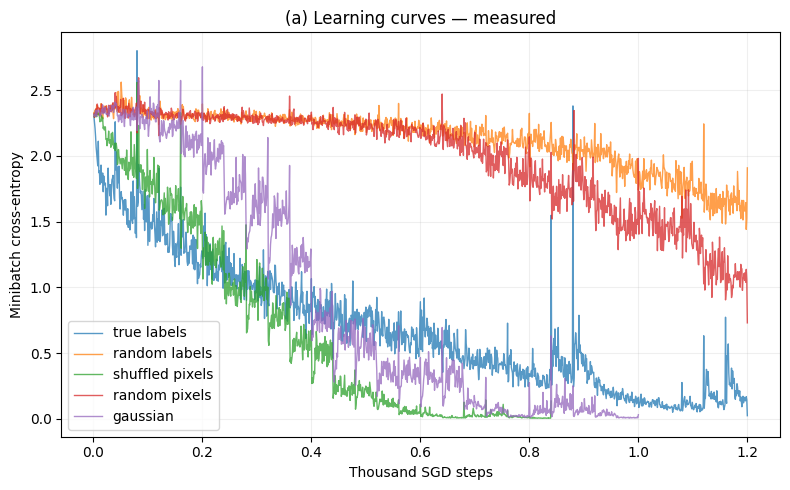

In [5]:
conditions=[('true labels','clean',0),('random labels','clean',1),
            ('shuffled pixels','shuffled_pixels',0),('random pixels','random_pixels',0),
            ('gaussian','gaussian',0)]
panel_a={}
for j,(name,mode,pval) in enumerate(conditions):
    a,y,b,z=make_condition(mode,pval,seed=1000+j)
    panel_a[name]=train_run('Inception (approx)',a,y,b,z,'a_'+name.replace(' ','_'))

fig,ax=plt.subplots(figsize=(8,5))
for name,r in panel_a.items():
    ax.plot(np.array(r['steps'])/1000,r['batch_losses'],label=name,alpha=.75,linewidth=1)
ax.set(xlabel='Thousand SGD steps',ylabel='Minibatch cross-entropy',title='(a) Learning curves — measured')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout();fig.savefig(OUT/'figure1a.png',dpi=180);plt.show()

## Figure 1(b,c): label corruption grid
Every architecture is trained from scratch at each corruption level. All runs use the same training subset and clean test subset. A point is missing from (b) when either the baseline or corrupted run did not meet the predefined training-error threshold. In (c), unfilled markers denote runs that had not converged by the budget limit.

grid_Inception_approx_0.0 epoch 1 train_error 0.8004 steps 40
grid_Inception_approx_0.0 epoch 10 train_error 0.501 steps 400
grid_Inception_approx_0.0 epoch 20 train_error 0.2722 steps 800
grid_Inception_approx_0.0 epoch 30 train_error 0.0174 steps 1200
grid_Inception_approx_0.5 epoch 1 train_error 0.8086 steps 40
grid_Inception_approx_0.5 epoch 10 train_error 0.6948 steps 400
grid_Inception_approx_0.5 epoch 20 train_error 0.7282 steps 800
grid_Inception_approx_0.5 epoch 30 train_error 0.3068 steps 1200
grid_Inception_approx_1.0 epoch 1 train_error 0.8918 steps 40
grid_Inception_approx_1.0 epoch 10 train_error 0.8288 steps 400
grid_Inception_approx_1.0 epoch 20 train_error 0.8024 steps 800
grid_Inception_approx_1.0 epoch 30 train_error 0.7322 steps 1200
grid_AlexNet_approx_0.0 epoch 1 train_error 0.7404 steps 40
grid_AlexNet_approx_0.0 epoch 10 train_error 0.3766 steps 400
grid_AlexNet_approx_0.0 epoch 20 train_error 0.0634 steps 800
grid_AlexNet_approx_0.0 epoch 26 train_error 0.0048 

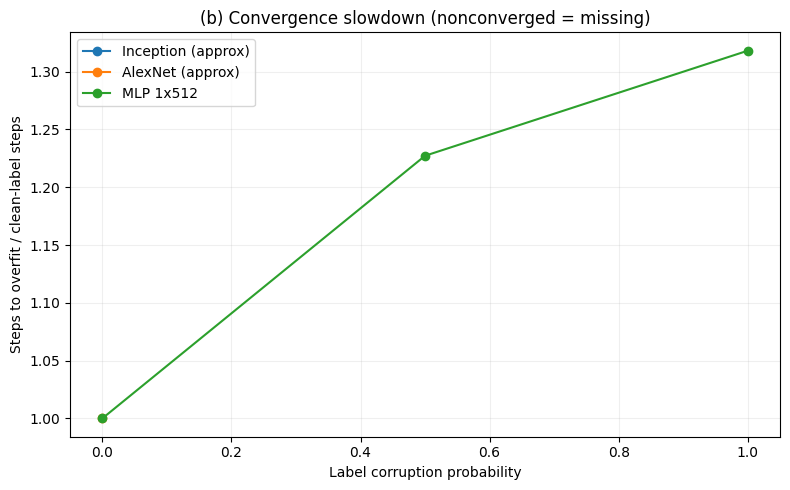

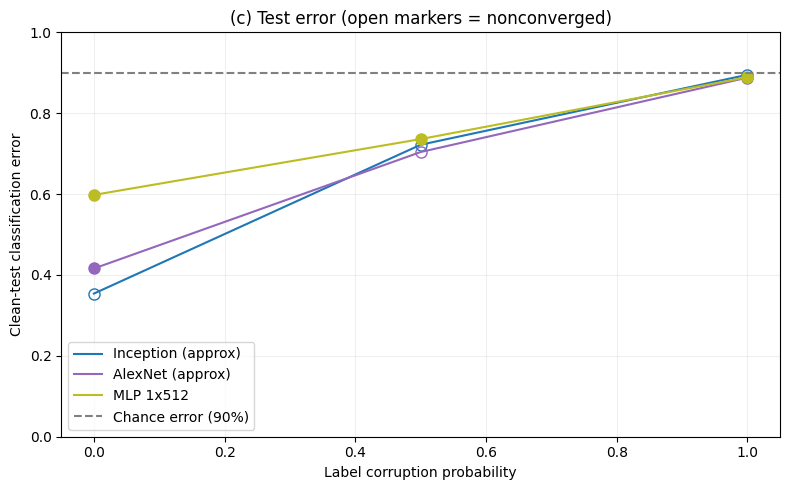

In [6]:
grid={}
for model_name in MODELS:
    grid[model_name]={}
    for j,pval in enumerate(LEVELS):
        a,y,b,z=make_condition('clean',pval,seed=3000+j)
        run_id='grid_'+model_name.replace(' ','_').replace('(','').replace(')','')+'_'+str(pval)
        grid[model_name][pval]=train_run(model_name,a,y,b,z,run_id)

fig,ax=plt.subplots(figsize=(8,5))
for model_name,runs in grid.items():
    base=runs[0.0]['converged_step']
    values=[(runs[p]['converged_step']/base if base is not None and runs[p]['converged_step'] is not None else np.nan) for p in LEVELS]
    ax.plot(LEVELS,values,'o-',label=model_name)
ax.set(xlabel='Label corruption probability',ylabel='Steps to overfit / clean-label steps',
       title='(b) Convergence slowdown (nonconverged = missing)')
ax.grid(alpha=.2);ax.legend();fig.tight_layout();fig.savefig(OUT/'figure1b.png',dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(8,5))
for model_name,runs in grid.items():
    values=[runs[p]['test_error'] for p in LEVELS]
    line,=ax.plot(LEVELS,values,'-',label=model_name)
    for p in LEVELS:
        ax.plot(p,runs[p]['test_error'],marker='o',linestyle='None',
                markerfacecolor=line.get_color() if runs[p]['converged_step'] is not None else 'none',
                markeredgecolor=line.get_color(),markersize=8)
ax.axhline(.9,linestyle='--',color='gray',label='Chance error (90%)')
ax.set(xlabel='Label corruption probability',ylabel='Clean-test classification error',
       ylim=(0,1),title='(c) Test error (open markers = nonconverged)')
ax.grid(alpha=.2);ax.legend();fig.tight_layout();fig.savefig(OUT/'figure1c.png',dpi=180);plt.show()

## Auditable numeric results and interpretation
The following tables are computed from runs, not entered by hand. A convergence step of `None` indicates right censoring. **Only when train error is zero is test error numerically equal to the generalization gap.** Compare trends with Figure 1 rather than expecting the same absolute numbers under the reduced data/architecture/epoch budget.

In [7]:
import pandas as pd
rows=[]
for model_name,runs in grid.items():
    for pval,r in runs.items():
        rows.append({'model':model_name,'p':pval,'steps_run':r['total_steps'],
                     'steps_to_threshold':r['converged_step'],
                     'train_error':r['train_error'],'test_error':r['test_error'],
                     'generalization_gap':r['generalization_gap'],
                     'seconds':r['elapsed_seconds']})
summary=pd.DataFrame(rows)
display(summary)
summary.to_csv(OUT/'summary.csv',index=False)
print('Saved measured curves, per-run JSON logs, and summary under:',OUT.resolve())

,model,p,steps_run,steps_to_threshold,train_error,test_error,generalization_gap,seconds
0,Inception (approx),0.0,1200,NaN,0.0174,0.354,0.3366,26.272288
1,Inception (approx),0.5,1200,NaN,0.3068,0.722,0.4152,26.201272
2,Inception (approx),1.0,1200,NaN,0.7322,0.895,0.1628,26.340713
3,AlexNet (approx),0.0,1040,1040.0,0.0048,0.416,0.4112,23.756390
4,AlexNet (approx),0.5,1200,NaN,0.3326,0.704,0.3714,27.139225
5,AlexNet (approx),1.0,1200,NaN,0.6606,0.888,0.2274,27.220546
6,MLP 1x512,0.0,880,880.0,0.0050,0.598,0.5930,2.670038
7,MLP 1x512,0.5,1080,1080.0,0.0048,0.736,0.7312,3.292575
8,MLP 1x512,1.0,1160,1160.0,0.0036,0.889,0.8854,3.579292


Saved measured curves, per-run JSON logs, and summary under: /content/figure1_outputs


## Reproducibility checklist and interpretation
- Record PyTorch, torchvision, Python, device, seed, sample counts, optimizer and model parameter counts.
- Runs share the same deterministic subset. The data and label corruption remain fixed across epochs.
- The experiment deliberately excludes augmentation, weight decay and dropout; BatchNorm in the approximate Inception is retained as part of the architecture.
- `torch.backends.cudnn.deterministic` may be enabled for stronger CUDA repeatability, with performance tradeoffs; exact reproducibility can vary by device and library version.
- If (b) contains gaps, **increase epochs** rather than interpolating or fabricating convergence times. If all random-label runs fail to converge, that is an inconclusive budget-limited reproduction, not a refutation of the paper.
- An observed increase in test error with corruption supports the qualitative result, but it does not establish the paper's exact published numbers under these deviations.


In [8]:
import platform
print({'python':platform.python_version(),'torch':torch.__version__,
       'torchvision':torchvision.__version__,'device':str(DEVICE),
       'seed':SEED,'train_n':TRAIN_N,'test_n':TEST_N,'epochs_budget':EPOCHS,
       'batch_size':BATCH_SIZE,'levels':LEVELS})

{'python': '3.13.15', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'device': 'cuda', 'seed': 42, 'train_n': 5000, 'test_n': 1000, 'epochs_budget': 30, 'batch_size': 128, 'levels': [0.0, 0.5, 1.0]}
